In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
!pip -q install kagglehub

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

np.random.seed(42)
tf.random.set_seed(42)

dataset_path = kagglehub.dataset_download(
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
)

csv_path = os.path.join(dataset_path, "IMDB Dataset.csv")
df = pd.read_csv(csv_path)

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
display(df.head())

print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.dropna().drop_duplicates().reset_index(drop=True)

df["sentiment"] = df["sentiment"].str.lower().map({
    "positive": 1,
    "negative": 0
})

df = df.dropna(subset=["sentiment"]).copy()
df["sentiment"] = df["sentiment"].astype(int)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["review"] = df["review"].apply(clean_text)

print("\nDataset after cleaning:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts().rename(
    index={1: "Positive", 0: "Negative"}
))

X = df["review"].values
y = df["sentiment"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

VOCAB_SIZE = 20000
MAX_LENGTH = 200
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token=OOV_TOKEN
)
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)
X_val_pad = pad_sequences(
    val_sequences, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    test_sequences, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)

print("\nVocabulary size:", min(VOCAB_SIZE, len(tokenizer.word_index) + 1))
print("Padded training shape:", X_train_pad.shape)
print("Padded validation shape:", X_val_pad.shape)
print("Padded testing shape:", X_test_pad.shape)

sample_review = X_train[0]
sample_sequence = tokenizer.texts_to_sequences([sample_review])[0]

print("\nSample review:")
print(sample_review[:500])
print("\nFirst 20 token IDs:", sample_sequence[:20])
print("\nPadded sequence shape:",
      pad_sequences([sample_sequence], maxlen=MAX_LENGTH).shape)

Name: Divyadharshini S
Roll no: 24BAD022
Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.

Dataset shape: (50000, 2)

Column names: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Missing values:
 review       0
sentiment    0
dtype: int64

Duplicate rows: 418

Dataset after cleaning: (49582, 2)

Sentiment distribution:
sentiment
Positive    24884
Negative    24698
Name: count, dtype: int64

Training samples: 39665
Validation samples: 4958
Testing samples: 4959

Vocabulary size: 20000
Padded training shape: (39665, 200)
Padded validation shape: (4958, 200)
Padded testing shape: (4959, 200)

Sample review:
i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several patients become seriously ill from pathogens induced by transfused blood i have also heard several jehovah's witnesses being told that they will die if they refuse blood and after years in the field i have never actually seen it happen leaving the ques

First 20 token IDs: [10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8,

In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

EMBEDDING_DIM = 64

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_LENGTH,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nLSTM Model Architecture:")
model.build(input_shape=(None, MAX_LENGTH))
model.summary()

Name: Divyadharshini S
Roll no: 24BAD022

LSTM Model Architecture:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

Name: Divyadharshini S
Roll no: 24BAD022
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 147s 474ms/step - accuracy: 0.9362 - loss: 0.1764 - val_accuracy: 0.8685 - val_loss: 0.3757
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 182s 408ms/step - accuracy: 0.9455 - loss: 0.1516 - val_accuracy: 0.8622 - val_loss: 0.4624
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 142s 408ms/step - accuracy: 0.9530 - loss: 0.1364 - val_accuracy: 0.8578 - val_loss: 0.5255


,Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,1,0.9362,0.8685,0.1764,0.3757
1,2,0.9455,0.8622,0.1516,0.4624
2,3,0.9530,0.8578,0.1364,0.5255


Test Loss: 0.395
Test Accuracy: 0.8643
Accuracy : 0.8643
Precision: 0.8982
Recall   : 0.8228
F1-score : 0.8589

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.91      0.87      2470
    Positive       0.90      0.82      0.86      2489

    accuracy                           0.86      4959
   macro avg       0.87      0.86      0.86      4959
weighted avg       0.87      0.86      0.86      4959



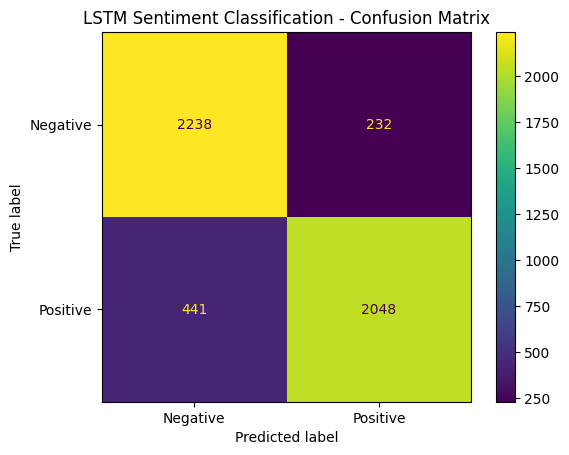

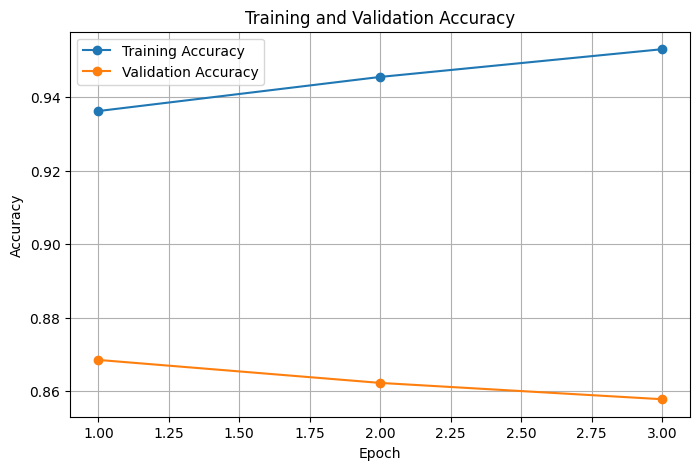

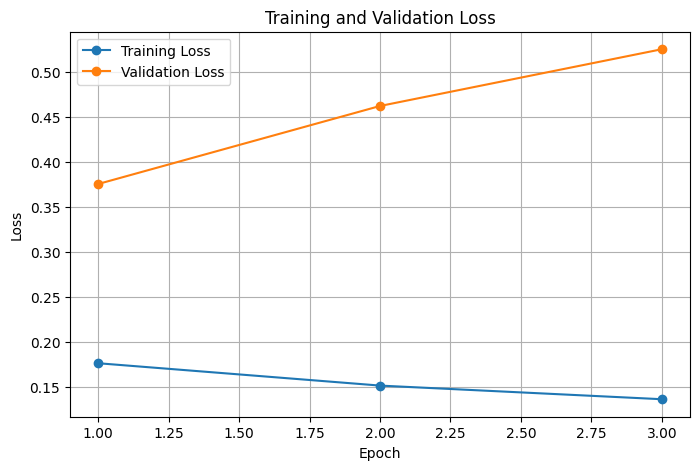

In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
EPOCHS = 5
BATCH_SIZE = 128

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)
history = model.fit(
    X_train_pad,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_pad, y_val),
    callbacks=[early_stopping],
    verbose=1
)

results_df = pd.DataFrame({
    "Epoch": range(1, len(history.history["accuracy"]) + 1),
    "Training Accuracy": history.history["accuracy"],
    "Validation Accuracy": history.history["val_accuracy"],
    "Training Loss": history.history["loss"],
    "Validation Loss": history.history["val_loss"]
})

display(results_df.round(4))

test_loss, test_accuracy = model.evaluate(
    X_test_pad, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))

y_prob = model.predict(X_test_pad, verbose=0).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display_matrix.plot(values_format="d")
plt.title("LSTM Sentiment Classification - Confusion Matrix")
plt.show()

epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["loss"], marker="o",
         label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
def predict_sentiment(review):
    cleaned_review = clean_text(review)
    sequence = tokenizer.texts_to_sequences([cleaned_review])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )
    probability = float(model.predict(padded_sequence, verbose=0)[0][0])
    sentiment = "Positive" if probability >= 0.5 else "Negative"
    return sentiment, probability

test_reviews = [
    {
        "review": "This movie was fantastic, entertaining, and beautifully acted.",
        "expected": "Positive"
    },
    {
        "review": "The film was boring, poorly written, and a complete waste of time.",
        "expected": "Negative"
    },
    {
        "review": "I loved the story and the actors gave excellent performances.",
        "expected": "Positive"
    },
    {
        "review": "The plot was confusing and the ending was very disappointing.",
        "expected": "Negative"
    },
    {
        "review": "An enjoyable movie with a great script and wonderful music.",
        "expected": "Positive"
    },
    {
        "review": "I disliked this film because it was slow and uninteresting.",
        "expected": "Negative"
    }
]

prediction_results = []

for item in test_reviews:
    predicted, probability = predict_sentiment(item["review"])

    prediction_results.append({
        "Review": item["review"],
        "Expected Sentiment": item["expected"],
        "Predicted Sentiment": predicted,
        "Positive Probability": round(probability, 4),
        "Correct": predicted == item["expected"]
    })

prediction_df = pd.DataFrame(prediction_results)
display(prediction_df)

correct_predictions = prediction_df["Correct"].sum()
total_predictions = len(prediction_df)

print("Total sample reviews:", total_predictions)
print("Correct predictions:", correct_predictions)
print(
    "Accuracy on these example reviews:",
    round(correct_predictions / total_predictions, 4)
)

print("\nObservation:")
print(
    "The model predicts sentiment based on patterns learned from the IMDB "
    "training reviews. Incorrect predictions may occur when a review contains "
    "sarcasm, mixed opinions, or wording that differs from the training data."
)

import json
model.save("lstm_sentiment_model.keras")
with open("tokenizer.json", "w", encoding="utf-8") as file:
    file.write(tokenizer.to_json())

print("Model saved as lstm_sentiment_model.keras")
print("Tokenizer saved as tokenizer.json")

Name: Divyadharshini S
Roll no: 24BAD022


,Review,Expected Sentiment,Predicted Sentiment,Positive Probability,Correct
0,"This movie was fantastic, entertaining, and be...",Positive,Positive,0.9716,True
1,"The film was boring, poorly written, and a com...",Negative,Negative,0.0024,True
2,I loved the story and the actors gave excellen...,Positive,Positive,0.9915,True
3,The plot was confusing and the ending was very...,Negative,Negative,0.1103,True
4,An enjoyable movie with a great script and won...,Positive,Positive,0.9868,True
5,I disliked this film because it was slow and u...,Negative,Negative,0.0363,True


Total sample reviews: 6
Correct predictions: 6
Accuracy on these example reviews: 1.0

Observation:
The model predicts sentiment based on patterns learned from the IMDB training reviews. Incorrect predictions may occur when a review contains sarcasm, mixed opinions, or wording that differs from the training data.
Model saved as lstm_sentiment_model.keras
Tokenizer saved as tokenizer.json
